In [18]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
from collections import Counter
from tqdm.contrib import tzip
from src.util import *
from src.preprocess import *
from src.config import *
import cv2

## 1. 데이터 로드 

파일이름변경

In [3]:
# 기존파일명 : test_case2_vel_0.5_data...... 
# 변경파일명 : raw_0.5

data_path = "dataset/raw/"
filelst = os.listdir(data_path)
try:
    for i in filelst:
        wind_value = i.split("_")[3]
        new_name = "raw_"+wind_value+".dat"
        os.rename(data_path+i,data_path+new_name)
    print("데이터명 변경완료")
except:
    print("이미 변경되어 있습니다.")
    pass


이미 변경되어 있습니다.


한개 데이터 분석

In [4]:
data_path = "dataset/raw/"
filelst = os.listdir(data_path)
with open(data_path+filelst[11]) as datafiles:
    data = datafiles.readlines()

In [8]:
# x 차이 0.65 전체길이 120
# y 차이 0.65 전체길이 80
# z 차이 0.65 전체길이 30

print("===== Data 정보 =====")
print(f"데이터 길이 :{len(data)}")
print(f"데이터 속성값 :{data[0]}")

===== Data 정보 =====
데이터 길이 :1080772
데이터 속성값 :variables=x,y,z,u,v,w,Density,Pressure,Nearby_Struct



## 2. 데이터 가공 및 장애물 위치확인

In [9]:
simul_config = simulaion_config()
x_dim = simul_config.x_dim
y_dim = simul_config.y_dim
z_dim = simul_config.z_dim

In [11]:
df = make_dataframe(data) # dataframe 생성
df = manipulate_dataframe(df,[x_dim,y_dim,z_dim],"vel_mag") # 정렬

In [12]:
df

,x,y,z,vel_mag
0,-59.8,-41.0,0.000000,0.017376
1,-59.8,-41.0,0.748718,3.250000
2,-59.8,-41.0,1.497436,3.250000
3,-59.8,-41.0,2.246154,3.250000
4,-59.8,-41.0,2.994872,3.250000
...,...,...,...,...
599995,59.8,41.0,26.205128,3.359285
599996,59.8,41.0,26.953846,3.360299
599997,59.8,41.0,27.702564,3.416255
599998,59.8,41.0,28.451282,3.425308


In [19]:
# 컬럼추가
df["Boundary"] = 1

# 속도값이 0인 부분은 Boundary를 0으로 지정
df.loc[df["vel_mag"]==0,"Boundary"]=0

# 배열 수 확인
Counter(df['Boundary'].values)

Counter({1: 572205, 0: 27795})

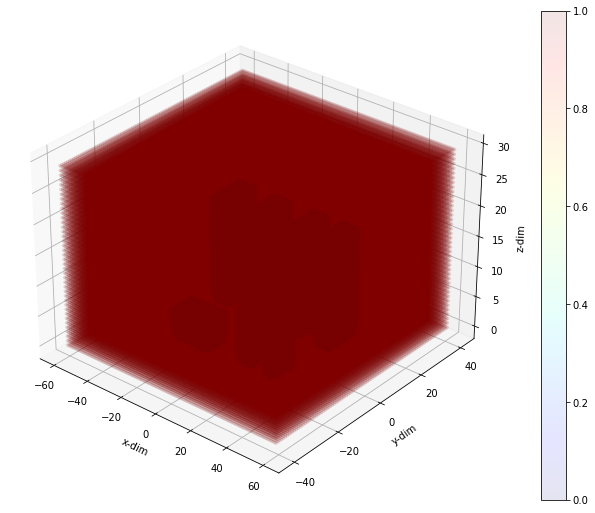

In [20]:
# Boundary plotting
obstacle = 1
non_obstacle = 0
setting_lst = [16,9,7,0.1,non_obstacle,obstacle,30,310]
plotting(df,df["Boundary"],setting_lst)

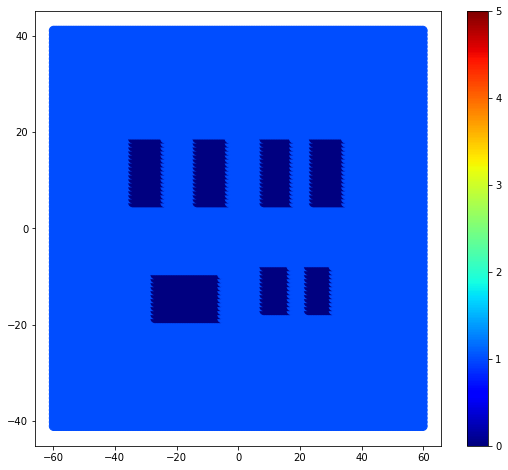

In [25]:
# 단면으로 결과확인 
# xy단면을 보기 위해 z값 고정
position_z_idx = 5
z_lst = sorted(list(set(df["z"]))) # 고정될 z값 
condition_z = df["z"]==z_lst[position_z_idx] # z 조건 정의
x = df[condition_z]["x"]
y = df[condition_z]["y"]
plot_data = df[condition_z]["Boundary"]

plt.figure(figsize=[20,8])
plt.subplot(1,2,1)
plt.scatter(x,y,c=plot_data, marker="o", s=80, cmap='jet', label="Label", vmin=0, vmax=5)
plt.colorbar()

## 3. 시뮬레이션 결과 확인

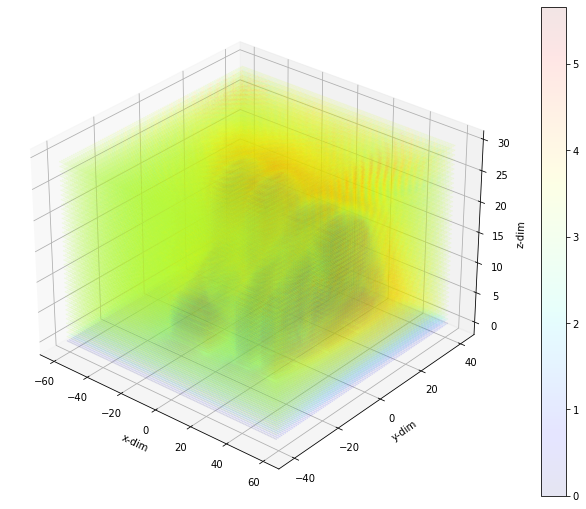

In [26]:
# simulation plotting
min_vel_mag = min(df["vel_mag"])
max_vel_mag = max(df["vel_mag"])
setting_lst = [16,9,0.5,0.1,min_vel_mag,max_vel_mag,30,310]
plotting(df,df["vel_mag"],setting_lst)

In [27]:
# Pyvista Plot
opt_list=[0.1,0.6,10,0.4,0,0.49]
plot_data = df["vel_mag"].values
plot=plot_data.reshape(x_dim*y_dim*z_dim)
array_list=[df["x"].values,df["y"].values,df["z"].values]
pyvista_plot(plot,opt_list,array_list)

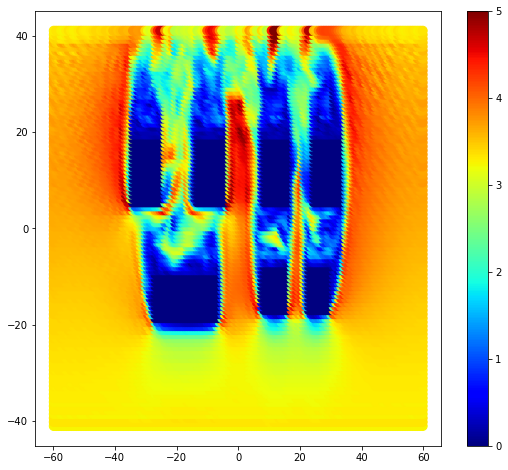

In [28]:
# 단면으로 결과확인 (z 고정)

position_z = 10
z_lst = sorted(list(set(df["z"]))) # 고정될 z값 
condition_z = df["z"]==z_lst[position_z_idx] # z 조건 정의
x = df[condition_z]["x"]
y = df[condition_z]["y"]
plot_data = df[condition_z]["vel_mag"]

plt.figure(figsize=[20,8])
plt.subplot(1,2,1)
plt.scatter(x,y,c=plot_data, marker="o", s=80, cmap='jet', label="Label", vmin=0, vmax=5)
plt.colorbar()

## 4. 데이터 가공

In [29]:
num_lst = []
for i in range(20):
    num = "00"+str(i)
    if len(num)>3:
        num = "0"+str(i)
    num_lst.append(num)

In [30]:
all_df = []
filelst = os.listdir(data_path)
for idx,i in tzip(num_lst,filelst):
    with open(data_path+i) as datafiles:
        data = datafiles.readlines()
        df = make_dataframe(data)
        aligned_df = manipulate_dataframe(df,[x_dim,y_dim,z_dim],"vel_mag")
        aligned_df["x"] = list(map(lambda x:round(x,4),aligned_df["x"].values))
        aligned_df["y"] = list(map(lambda x:round(x,4),aligned_df["y"].values))
        aligned_df["z"] = list(map(lambda x:round(x,4),aligned_df["z"].values))
    aligned_df.to_csv(f"dataset/processed/csv/{idx}_processed_"+i.split("_")[1]+".csv",index=False)
    all_df.append(aligned_df)

  0%|          | 0/20 [00:00<?, ?it/s]

KeyboardInterrupt: 